In [1]:
# Data manipulation
import pandas as pd
import numpy as np
# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns
# Machine learning
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

Matplotlib is building the font cache; this may take a moment.


In [2]:
# Creating a synthetic dataset
data = {
'TV_Advertising': [230, 44, 17, 151, 180, 8, 57, 120, 8, 200],
'Radio_Advertising': [37, 39, 45, 41, 10, 48, 32, 19, 2, 30],
'Social_Media': [69, 45, 69, 58, 12, 35, 23, 11, 1, 65],
'Sales': [22.1, 10.4, 9.3, 18.5, 12.9, 7.2, 11.8, 13.2, 4.8, 19.6]
}
df = pd.DataFrame(data)
df.head()

,TV_Advertising,Radio_Advertising,Social_Media,Sales
0,230,37,69,22.1
1,44,39,45,10.4
2,17,45,69,9.3
3,151,41,58,18.5
4,180,10,12,12.9


In [3]:
print(df.describe())
print(df.corr())

       TV_Advertising  Radio_Advertising  Social_Media      Sales
count       10.000000          10.000000      10.00000  10.000000
mean       101.500000          30.300000      38.80000  12.980000
std         85.036267          15.304683      26.03758   5.572113
min          8.000000           2.000000       1.00000   4.800000
25%         23.750000          21.750000      14.75000   9.575000
50%         88.500000          34.500000      40.00000  12.350000
75%        172.750000          40.500000      63.25000  17.175000
max        230.000000          48.000000      69.00000  22.100000
                   TV_Advertising  Radio_Advertising  Social_Media     Sales
TV_Advertising           1.000000          -0.108298      0.325083  0.917367
Radio_Advertising       -0.108298           1.000000      0.761640  0.218836
Social_Media             0.325083           0.761640      1.000000  0.592422
Sales                    0.917367           0.218836      0.592422  1.000000


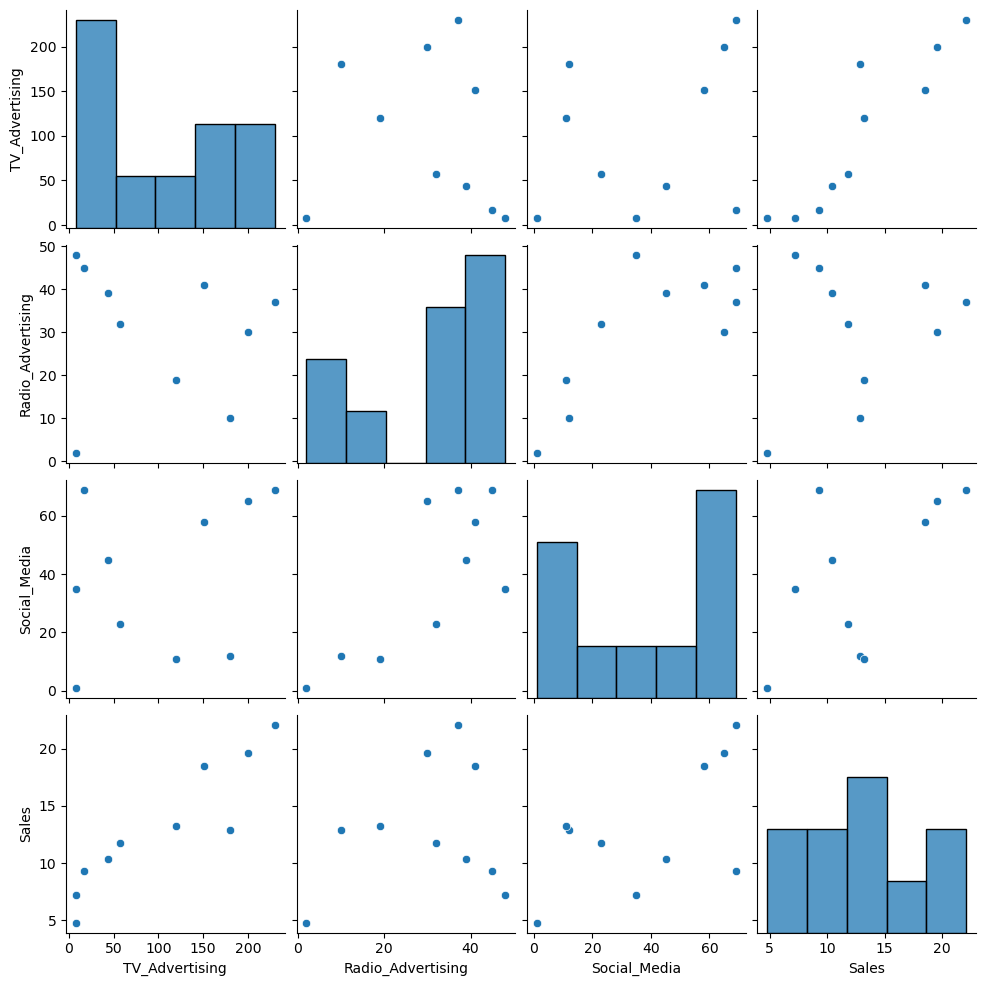

In [4]:
sns.pairplot(df)
plt.show()

In [5]:
X = df[['TV_Advertising', 'Radio_Advertising', 'Social_Media']]
y = df['Sales']

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
X, y, test_size=0.3, random_state=42
)

In [7]:
model = LinearRegression()
model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [8]:
print("Intercept:", model.intercept_)
print("Coefficients:", model.coef_)

Intercept: -1.4713326667115432
Coefficients: [ 0.07194242  0.31949767 -0.06312111]


In [9]:
y_pred = model.predict(X_test)

In [11]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 3.6882894218070597
RMSE: 4.177664869960861
R2 Score: -2.316637539935511


In [12]:
new_data = pd.DataFrame({
'TV_Advertising': [150],
'Radio_Advertising': [25],
'Social_Media': [40]
})
forecast = model.predict(new_data)
print("Forecasted Sales:", forecast[0])

Forecasted Sales: 14.7826271636639


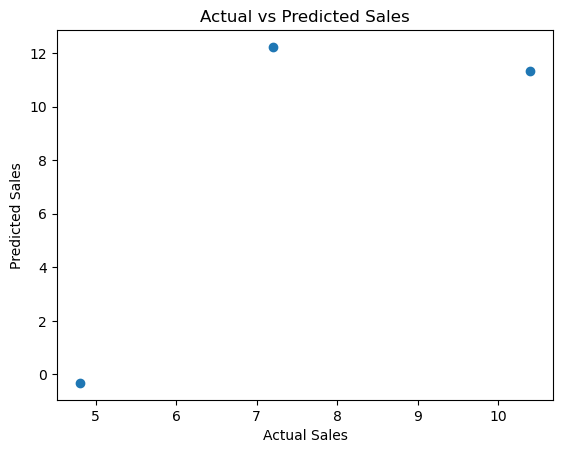

In [13]:
plt.scatter(y_test, y_pred)
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Sales")
plt.show()